# Caso de Negocio: Retención de clientes Interconnect

## Objetivo

El objetivo del presente trabajo es desarrollar un modelo que permita a Interconnect identificar a los clientes con riesgo de cancelación. De esta manera Interconnect puede realizar acciones preventivas de retención mediante planes especiales para motivar la permanencia del cliente.

# 1. Preparación e integración de información.

In [1]:
# Inclusión de librerias y herramientas
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
from lightgbm import LGBMClassifier


In [2]:
import sys
import lightgbm
import numpy
import sklearn

print("Python:", sys.version)
print("LightGBM:", lightgbm.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.12.5 (tags/v3.12.5:ff3bc82, Aug  6 2024, 20:45:27) [MSC v.1940 64 bit (AMD64)]
LightGBM: 4.6.0
NumPy: 2.5.4
Scikit-learn: 1.9.0


In [3]:
path = "data/"

contract = pd.read_csv(path + "contract.csv")
personal = pd.read_csv(path + "personal.csv")
internet = pd.read_csv(path + "internet.csv")
phone = pd.read_csv(path + "phone.csv")

print("Datos cargados correctamente")

Datos cargados correctamente


Preparación de los datos

In [4]:
print('contract:', contract.shape)
print('personal:', personal.shape)
print('internet:', internet.shape)
print('phone:', phone.shape)

contract: (7043, 8)
personal: (7043, 5)
internet: (5517, 8)
phone: (6361, 2)


In [5]:
# revisamos las variables en los archivos
print('CONTRACT:')
display(contract.head())
print('PERSONAL:')
display(personal.head())
print('INTERNET:')
display(internet.head())
print('PHONE:')
display(phone.head())

CONTRACT:


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


PERSONAL:


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


INTERNET:


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No


PHONE:


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


In [6]:
# revisamos los tipos de datos
print('====CONTRACT=====')
contract.info()
print()
print("====PERSONAL=====")
personal.info()
print()
print("====INTERNET=====")
internet.info()
print()
print("====PHONE=====")
phone.info()

====CONTRACT=====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB

====PERSONAL=====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner

In [7]:
# revisando integridad de la información
print('Duplicados:')
print('contract:', contract.duplicated().sum())
print('personal:', personal.duplicated().sum())
print('internet:', internet.duplicated().sum())
print('phone:', phone.duplicated().sum())

print("\nValores de EndDate:")
print(contract['EndDate'].value_counts())

print("\nTipos de valores de TotalCharges:")
print(contract['TotalCharges'].value_counts().head(10))

Duplicados:
contract: 0
personal: 0
internet: 0
phone: 0

Valores de EndDate:
EndDate
No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: count, dtype: int64

Tipos de valores de TotalCharges:
TotalCharges
20.2     11
         11
19.75     9
19.65     8
19.9      8
20.05     8
19.55     7
45.3      7
19.45     6
20.25     6
Name: count, dtype: int64


In [8]:
# zoom en valores vacios de la variable TotalCharges
print('Valores vacios en TotalCharges:')
print((contract['TotalCharges'].str.strip() == "").sum())
print()
print("Registros con TotalCharges vacio:")

display(contract[contract['TotalCharges'].str.strip() == ""])


Valores vacios en TotalCharges:
11

Registros con TotalCharges vacio:


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,Two year,Yes,Bank transfer (automatic),52.55,
753,3115-CZMZD,2020-02-01,No,Two year,No,Mailed check,20.25,
936,5709-LVOEQ,2020-02-01,No,Two year,No,Mailed check,80.85,
1082,4367-NUYAO,2020-02-01,No,Two year,No,Mailed check,25.75,
1340,1371-DWPAZ,2020-02-01,No,Two year,No,Credit card (automatic),56.05,
3331,7644-OMVMY,2020-02-01,No,Two year,No,Mailed check,19.85,
3826,3213-VVOLG,2020-02-01,No,Two year,No,Mailed check,25.35,
4380,2520-SGTTA,2020-02-01,No,Two year,No,Mailed check,20.00,
5218,2923-ARZLG,2020-02-01,No,One year,Yes,Mailed check,19.70,
6670,4075-WKNIU,2020-02-01,No,Two year,No,Mailed check,73.35,


In [9]:
# validacion de la variable 'customerid' como valor único
print('CustomerID únicos:')
print('contract:', contract['customerID'].nunique())
print('personal:', contract['customerID'].nunique())
print('internet:', contract['customerID'].nunique())
print('phone:', contract['customerID'].nunique())
print()
print('Filas vs CustomerID únicos:')
print('contract:', len(contract), contract['customerID'].nunique())
print('personal:', len(contract), personal['customerID'].nunique())
print('internet:', len(contract), internet['customerID'].nunique())
print('phone:', len(contract), phone['customerID'].nunique())


CustomerID únicos:
contract: 7043
personal: 7043
internet: 7043
phone: 7043

Filas vs CustomerID únicos:
contract: 7043 7043
personal: 7043 7043
internet: 7043 5517
phone: 7043 6361


In [10]:
# validación de filas de df's Internet y Phone
print('INTERNET:')
print('Filas:', len(internet))
print('Columnas:', len(internet.columns))
print('CustomerID únicos:', internet['customerID'].nunique())
print()
print('PHONE:')
print('Filas:', len(phone))
print('Columnas:', len(phone.columns))
print('CustomerID únicos:', phone['customerID'].nunique())

INTERNET:
Filas: 5517
Columnas: 8
CustomerID únicos: 5517

PHONE:
Filas: 6361
Columnas: 2
CustomerID únicos: 6361


In [11]:
# revisamos las variables categóricas
print('CONTRACT:')
for column in contract.columns:
    if contract[column].dtype == 'object':
        print(f'\n{column}:')
        print(contract[column].value_counts().head(10))

print()
print('PERSONAL:')
for column in personal.columns:
    if personal[column].dtype == 'object':
        print(f'\n{column}:')
        print(personal[column].value_counts().head(10))

print()
print('INTERNET:')
for column in internet.columns:
    if internet[column].dtype == 'object':
        print(f'\n{column}:')
        print(internet[column].value_counts().head(10))

print()
print('PHONE:')
for column in phone.columns:
    if phone[column].dtype == 'object':
        print(f'\n{column}:')
        print(phone[column].value_counts().head(10))

CONTRACT:

customerID:
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
Name: count, dtype: int64

BeginDate:
BeginDate
2014-02-01    366
2019-09-01    237
2019-10-01    237
2019-11-01    237
2020-01-01    233
2019-12-01    220
2014-03-01    178
2019-07-01    156
2019-08-01    146
2019-06-01    141
Name: count, dtype: int64

EndDate:
EndDate
No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: count, dtype: int64

Type:
Type
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaperlessBilling:
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: cou

In [12]:
# revisamos variables numéricas de los df's de contract y personal
print('CONTRACT:')
display(contract[['MonthlyCharges']].describe())
print()
print('PERSONAL:')
display(personal[['SeniorCitizen']].describe())

CONTRACT:


,MonthlyCharges
count,7043.000000
mean,64.761692
std,30.090047
min,18.250000
25%,35.500000
50%,70.350000
75%,89.850000
max,118.750000



PERSONAL:


,SeniorCitizen
count,7043.000000
mean,0.162147
std,0.368612
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


In [13]:
# revisamos el periodo completo de la información 
print('===BEGIN DATE===')
print('Fecha mínima:', contract['BeginDate'].min())
print('Fecha máxima:', contract['BeginDate'].max())
print()
print('\n===END DATE===')
end_dates = contract.loc[contract['EndDate']!= 'No', 'EndDate']
print()
print('Fecha Mínima:', end_dates.min())
print('Fecha Máxima:', end_dates.max())

===BEGIN DATE===
Fecha mínima: 2013-10-01
Fecha máxima: 2020-02-01


===END DATE===

Fecha Mínima: 2019-10-01 00:00:00
Fecha Máxima: 2020-01-01 00:00:00


# Observaciones iniciales

Observaciones iniciales en el analisis exploratorio de los dataframes del estudio (7043 contract y personal): los DF's internet(5517), así como, phone (6361) tienen menos registros que los de contract y personal por lo que se tiene que confirmar si están los mismos clientes en los a archivos.

La variable 'EndDate'del df contract, tiene 2 tipos de valores: 'No' y Fechas, ya que esta servirá como objetivo se debe plantear como afectaría a la clase positiva, por otro lado, hay un moderado desbalance de clases en la misma siendo el 73.5% las de valor 'No'. 

La variable 'TotalCharges' es tipo Object la cual requiere atención por ser numérica y de posible valor predictivo. La causa de la clasificación de Object viene de los 11 registros en blanco dentr del df, se debe definir el tratamiento de los 11 casos vacios.

La variable 'customerID' la cual pretendemos usar como llave para la consolidación de los dataframes se ha confirmado como viable.

En el análisis de las variables categóricas encontramos una alta concentración en el tipo de contrato 'month-to-month', asi como en el método de pago 'Electronic check'.

Confirmamos que los registros de los dataframes de internet y phone se encuentran en su totalidad dentro de aquellos de contract y personal por lo que sabemos que existen clientes que no cuentan con servicio de internet o de teléfono que no deben ser descartados.

Las variables numéricas comenzando con 'MonthlyCharges' muestra una asimetría en su distribución ya que su mediana es de 64.76 y su promedio de 70.35 con una amplia dispersión de valores desvstd de 30.09, max. = 118.75 y mínimo de 18.25 sugiere mayor analisis para buscar causalidad. La antiguedad de los clientes también es tema de profundización dado que existen clientes con fechas de inicio distantes.

In [14]:
# consolidamos los 4 atchivos en uno solo para facilitar el análisis
df= contract.merge(personal, on = 'customerID', how = 'left')
df = df.merge(internet, on = 'customerID', how = 'left')
df = df.merge(phone, on = 'customerID', how = 'left')

print('Dimensión del DF consolidado:', df.shape)

Dimensión del DF consolidado: (7043, 20)


In [15]:
# Revisamos si hay valores nulos o vacios en la variable TotalCharges
df['TotalCharges'].isna().sum(), (df['TotalCharges']== '').sum()

(np.int64(0), np.int64(0))

In [16]:
print(df['TotalCharges'].dtypes)
print(df['TotalCharges'].head())

object
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
Name: TotalCharges, dtype: object


In [17]:
df[df['TotalCharges'].str.strip()==''][['customerID', 'BeginDate', 'MonthlyCharges', 'TotalCharges']]

,customerID,BeginDate,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,52.55,
753,3115-CZMZD,2020-02-01,20.25,
936,5709-LVOEQ,2020-02-01,80.85,
1082,4367-NUYAO,2020-02-01,25.75,
1340,1371-DWPAZ,2020-02-01,56.05,
3331,7644-OMVMY,2020-02-01,19.85,
3826,3213-VVOLG,2020-02-01,25.35,
4380,2520-SGTTA,2020-02-01,20.00,
5218,2923-ARZLG,2020-02-01,19.70,
6670,4075-WKNIU,2020-02-01,73.35,


In [18]:
# convertimos a las variable object TotalCharges en los tipos de datos necesarios para el análisis
df['TotalCharges']= pd.to_numeric(df['TotalCharges'], errors = 'coerce')
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isna().sum())

float64
11


In [19]:
df['BeginDate'] = pd.to_datetime(df['BeginDate'])
df['EndDate'] = pd.to_datetime(df['EndDate'], errors= 'coerce')
print(df[['BeginDate', 'EndDate']].dtypes)

BeginDate    datetime64[ns]
EndDate      datetime64[ns]
dtype: object


C:\Users\alanp\AppData\Local\Temp\ipykernel_21356\728111128.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['EndDate'] = pd.to_datetime(df['EndDate'], errors= 'coerce')


In [20]:
print(df['EndDate'].isna().sum())
print(df['EndDate'].notna().sum())


5174
1869


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7032 non-null   float64       
 8   gender            7043 non-null   object        
 9   SeniorCitizen     7043 non-null   int64         
 10  Partner           7043 non-null   object        
 11  Dependents        7043 non-null   object        
 12  InternetService   5517 non-null   object        
 13  OnlineSecurity    5517 non-null   object        
 14  OnlineBackup      5517 n

In [22]:
# revisamos el nuevo df consolidado
print('Clientes:', df['customerID'].nunique())
print('Filas:', len(df))

Clientes: 7043
Filas: 7043


# Definición de la variable objetivo


In [23]:
# creamos una columna que identifica la variable objetivo los clientes que cancelan
df['churn_eda'] = df['EndDate'].notna()

print(df['churn_eda'].value_counts())
print()
print(df['churn_eda'].value_counts(normalize = True))

churn_eda
False    5174
True     1869
Name: count, dtype: int64

churn_eda
False    0.73463
True     0.26537
Name: proportion, dtype: float64


In [24]:
# creamos una variable para conocer la permanencia de los clientes
df['BeginDate'] = pd. to_datetime(df['BeginDate'])
reference_date = pd.Timestamp("2020-02-01")
df['tenure_months'] = ((reference_date - df['BeginDate']).dt.days / 30.44).round(1)

In [25]:
# analizamos la permanencia de los clientes segun si cancelaron o no
df.groupby('churn_eda')['tenure_months'].describe()

,count,mean,std,min,25%,50%,75%,max
churn_eda,,,,,,,,
False,5174.0,37.588365,24.113888,0.0,15.0,38.0,61.0,72.0
True,1869.0,20.500910,19.581492,2.0,5.0,12.0,31.0,76.0


In [26]:
# analizamos los tipos de contrato
churn_by_type = pd.crosstab(df['Type'], df['churn_eda'], normalize = 'index')* 100
churn_by_type

churn_eda,False,True
Type,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


La tabla muestra una clara relación del churn con el tipo de contrato. Esta relación será considerada después en la fase de modelado

In [27]:
# analizamos los métodos de pago
churn_by_payment = pd.crosstab(df['PaymentMethod'], df['churn_eda'], normalize = 'index')*100
churn_by_payment

churn_eda,False,True
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


Los clientes en churn que usan el Electronic check como método de pago tienen un considerable mayor porcentaje que los otros. También consideramos este hallazgo en el modelado.

In [28]:
# Analizamos el servicio de internet según churn
churn_by_internet = pd.crosstab(df['InternetService'].fillna('No Internet'), df['churn_eda'], normalize = 'index')*100
churn_by_internet

churn_eda,False,True
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No Internet,92.595020,7.404980


El tipo de servicio de internet presenta diferencias importantes en la proporción del churn. Los clientes con Fiber Optic representan el 41.89% de la cancelación frente al 18.06% de tipo DSL y 7.40% sin servicio de internet. Consideramos este resultado para el posterior modelado.

In [29]:
churn_by_security = pd.crosstab(
    df['OnlineSecurity'].fillna('No internet'),
    df['churn_eda'],
    normalize='index'
) * 100

churn_by_security

churn_eda,False,True
OnlineSecurity,,
No,58.233276,41.766724
No internet,92.595020,7.404980
Yes,85.388806,14.611194


Los clientes sin el servicio OnlineSecurity presentan una mayor proporción de churn (41.7%) que los que si cuentan con el servicio (14.6%) y los clientes sin servicio de Internet solo tienen el 7.4%


In [30]:
churn_by_support = pd.crosstab(
    df['TechSupport'].fillna('No internet'),
    df['churn_eda'],
    normalize='index'
) * 100

churn_by_support

churn_eda,False,True
TechSupport,,
No,58.364526,41.635474
No internet,92.595020,7.404980
Yes,84.833659,15.166341


Los clientes sin TechSupport tienen un comportamiento similar a OnlineSecurity y el 41.63% cancelaron

In [31]:
# visualizamos las cifras de churn por otros tipos de servicio
service_cols = ['OnlineBackup', 'DeviceProtection', 'StreamingTV', 'StreamingMovies']
for col in service_cols:
    print(f'\n---col---')
    print(pd.crosstab(df[col].fillna('No Internet'), df['churn_eda'], normalize='index')*100)


---col---
churn_eda         False      True 
OnlineBackup                      
No            60.071244  39.928756
No Internet   92.595020   7.404980
Yes           78.468506  21.531494

---col---
churn_eda             False      True 
DeviceProtection                      
No                60.872375  39.127625
No Internet       92.595020   7.404980
Yes               77.497936  22.502064

---col---
churn_eda        False      True 
StreamingTV                      
No           66.476868  33.523132
No Internet  92.595020   7.404980
Yes          69.929812  30.070188

---col---
churn_eda            False      True 
StreamingMovies                      
No               66.319569  33.680431
No Internet      92.595020   7.404980
Yes              70.058565  29.941435


Los servicios adicionales muestran diferentes niveles de asociación con el churn. OnlineBackup y DeviceProtection presentan diferencias más marcadas entre clientes que cuentan o no con estos servicios, mientras que StreamingTV y StreamingMovies muestran diferencias menores. Los clientes sin servicio de internet presentan nuevamente una proporción de churn de 7.40%.

In [32]:
# como se mira el MonthlyCharges
df.groupby('churn_eda')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
churn_eda,,,,,,,,
False,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
True,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


Los clientes que cancelaron presentan cargos mensuales superiores a los clientes que permanecieron. La mediana de MonthlyCharges es de 79.65 para los clientes con churn, frente a 64.43 para quienes no cancelaron, lo que indica una asociación entre los cargos mensuales y el churn.

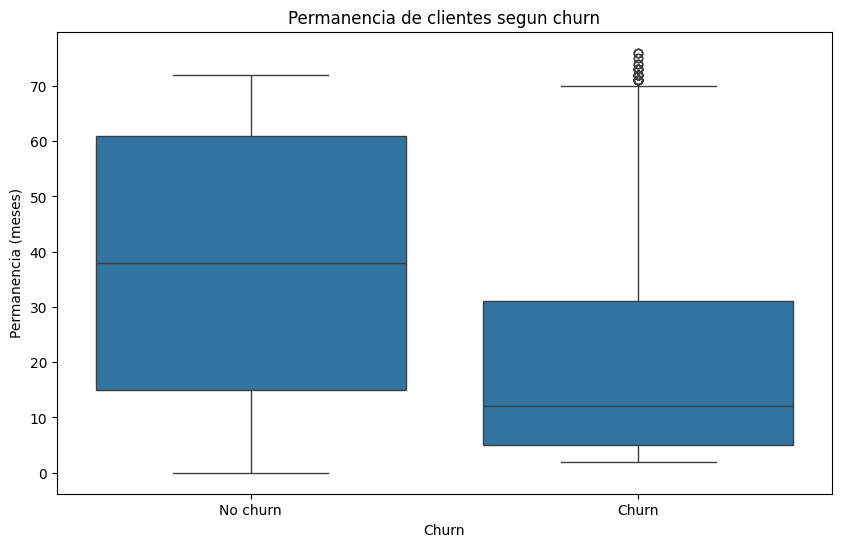

In [33]:
# graficamos permanencia
plt.figure(figsize = (10,6))
sns.boxplot(data = df, x = 'churn_eda', y = 'tenure_months' )
plt.xlabel('Churn')
plt.ylabel('Permanencia (meses)')
plt.title('Permanencia de clientes segun churn')
plt.xticks([0,1],['No churn', 'Churn'])
plt.show()

La permanencia de los clientes presenta una asociación clara con el churn. Los clientes que cancelaron muestran una permanencia considerablemente menor que los clientes que permanecen activos, con medianas aproximadas de 12 y 38 meses, respectivamente. Esto sugiere que los clientes con menor antigüedad podrían presentar mayor riesgo de cancelación.

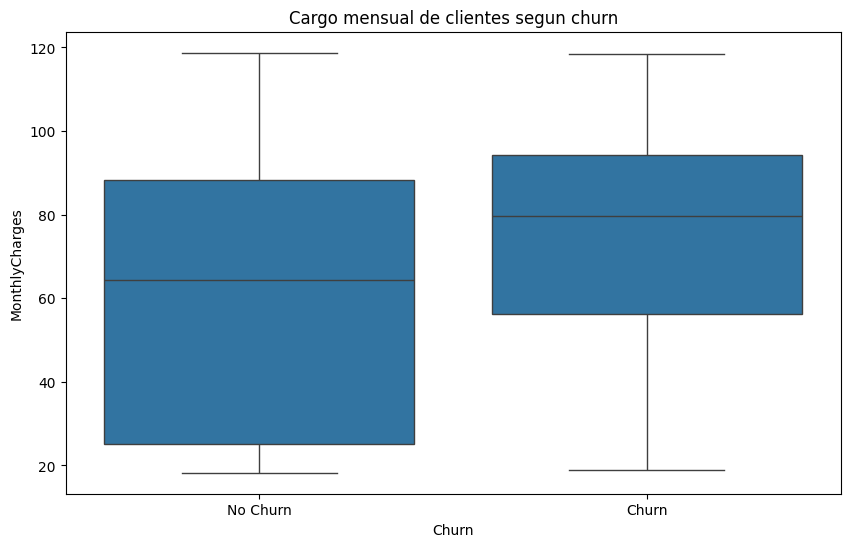

In [34]:
# graficamos los cargos mensuales
plt.figure(figsize=(10, 6))
sns.boxplot(data = df, x= 'churn_eda', y = 'MonthlyCharges')
plt.xlabel('Churn')
plt.ylabel('MonthlyCharges')
plt.title('Cargo mensual de clientes segun churn')
plt.xticks([0,1], ['No Churn', 'Churn'])
plt.show()

Los clientes que cancelaron presentan, en general, cargos mensuales más altos que los clientes que permanecen activos. La mediana del cargo mensual es aproximadamente 79.7 para los clientes con churn frente a 64.4 para los clientes sin churn. Esto muestra una asociación entre el nivel de cargo mensual y el churn, aunque esta variable por sí sola no permite explicar la cancelación.

In [35]:
# REVISAR ESTE CÓDIGO
print("plt.xlabel =", plt.xlabel)
print("tipo =", type(plt.xlabel))

plt.xlabel = <function xlabel at 0x000002FB80AA40E0>
tipo = <class 'function'>


In [36]:
# REVISAR ESTE PARCHE
print(type(plt.xlabel))

<class 'function'>


In [37]:
# PARCHE X REVISAR
plt = importlib.reload(plt)
print(type(plt.xlabel))

<class 'function'>


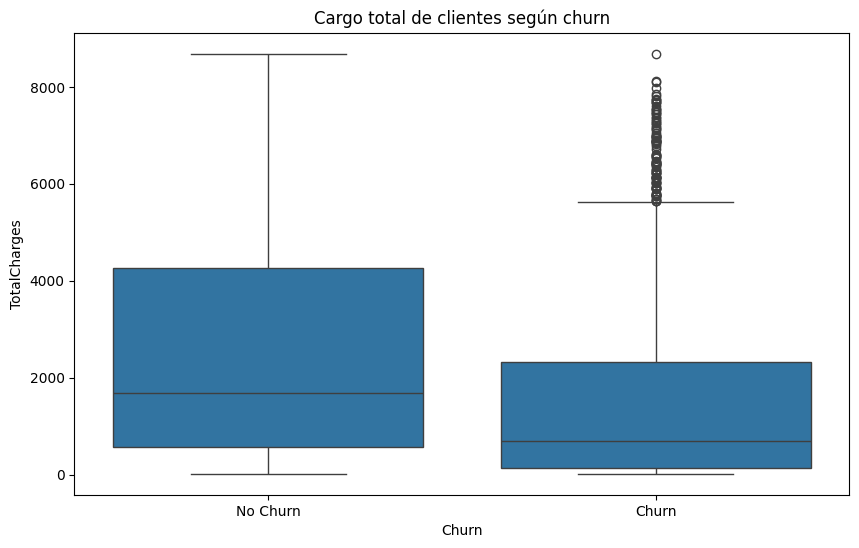

In [38]:
# graficamos los cargos totales
plt.figure(figsize = (10, 6))
sns.boxplot(data = df, x = 'churn_eda', y = 'TotalCharges')
plt.xlabel('Churn')
plt.ylabel('TotalCharges')
plt.title('Cargo total de clientes según churn')
plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.show()

Los clientes que cancelaron presentan cargos totales acumulados considerablemente menores que los clientes que permanecen activos, con medianas aproximadas de 704 y 1,684, respectivamente. Esta diferencia está relacionada con la menor permanencia observada entre los clientes que cancelaron. Los valores atípicos altos no se consideran automáticamente errores, ya que pueden corresponder a clientes con una permanencia prolongada antes de cancelar.

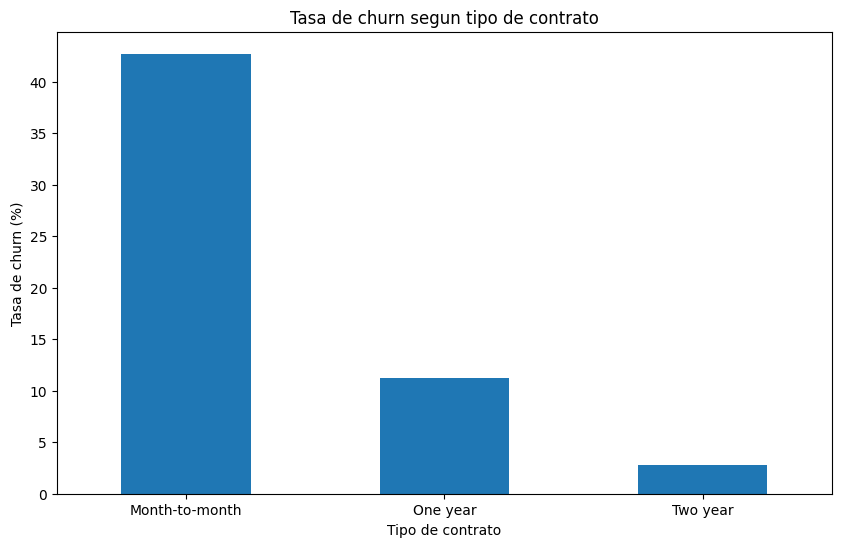

In [39]:
# Gráfica con cancelaciones por los tipos de contrato
churn_by_type = (pd.crosstab(df['Type'], df['churn_eda'], normalize = 'index')*100)
churn_type_pcnt = churn_by_type[True]

plt.figure(figsize= (10, 6))
churn_type_pcnt.plot(kind = 'bar')
plt.xlabel('Tipo de contrato')
plt.ylabel('Tasa de churn (%)')
plt.title('Tasa de churn segun tipo de contrato')
plt.xticks(rotation = 0)
plt.show()

El tipo de contrato presenta una asociación clara con el churn. La tasa de cancelación es considerablemente mayor entre los clientes con contratos mes a mes y disminuye en los contratos de uno y dos años.

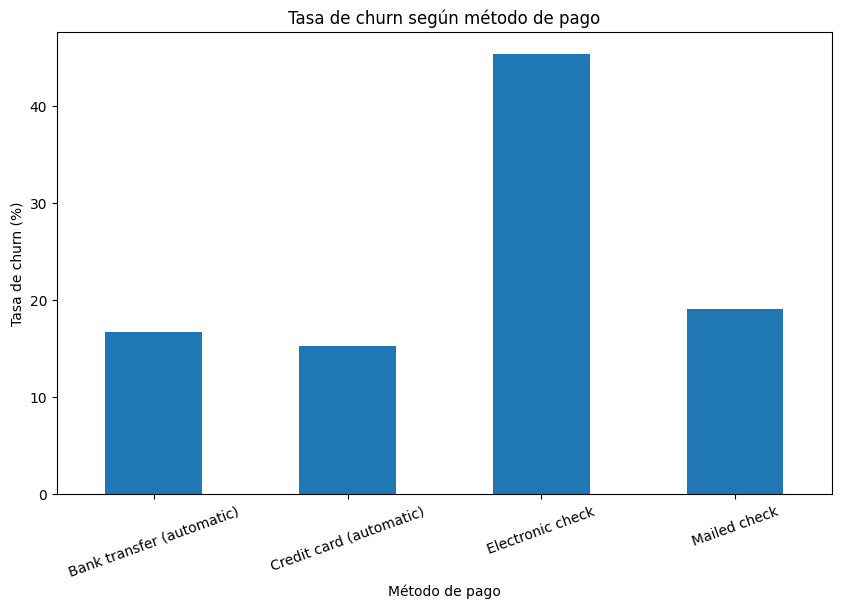

In [40]:
# Gráfica con churn por el método de pago
churn_by_payment = (
    pd.crosstab(
        df['PaymentMethod'],
        df['churn_eda'],
        normalize='index'
    ) * 100
)

churn_payment_pct = churn_by_payment[True]

plt.figure(figsize=(10, 6))
churn_payment_pct.plot(kind='bar')

plt.xlabel('Método de pago')
plt.ylabel('Tasa de churn (%)')
plt.title('Tasa de churn según método de pago')
plt.xticks(rotation=20)

plt.show()

El método de pago presenta una asociación con el churn. Los clientes que utilizan Electronic check muestran una tasa de cancelación considerablemente mayor (45.29%) que los demás métodos de pago.

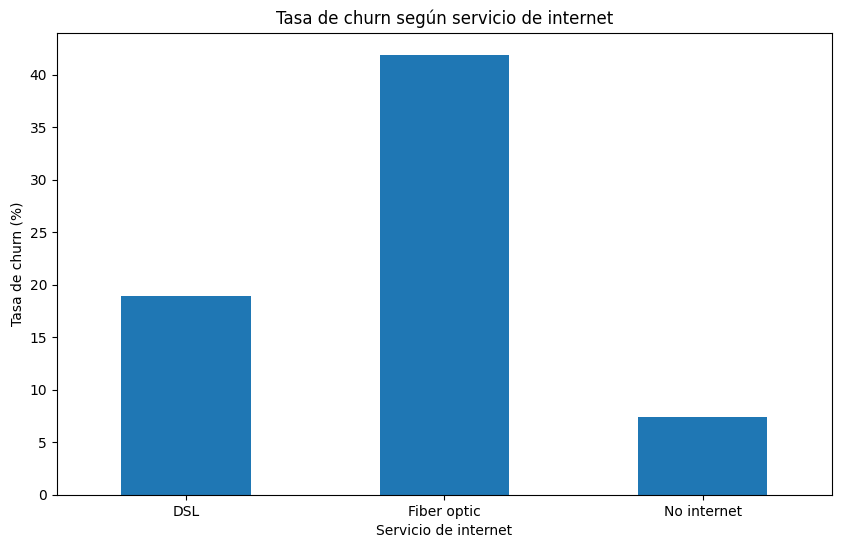

In [41]:
# cancelaciones de clientes de servicio de internet
churn_by_internet = (
    pd.crosstab(
        df['InternetService'].fillna('No internet'),
        df['churn_eda'],
        normalize='index'
    ) * 100
)

churn_internet_pct = churn_by_internet[True]

plt.figure(figsize=(10, 6))
churn_internet_pct.plot(kind='bar')

plt.xlabel('Servicio de internet')
plt.ylabel('Tasa de churn (%)')
plt.title('Tasa de churn según servicio de internet')
plt.xticks(rotation=0)

plt.show()

El servicio de internet presenta una asociación con el churn. Los clientes con servicio de fibra óptica muestran una tasa de cancelación considerablemente mayor que los clientes con DSL o sin servicio de internet.

Feature Engineering

In [42]:
# creamos la variable objetivo para el modelado
# 1 = cliente que canceló, 0 = cliente que continúa vigente
df['target'] = df['churn_eda'].astype(int)
print()
print('Variable objetivo (target):')
print(df['target'].value_counts())


Variable objetivo (target):
target
0    5174
1    1869
Name: count, dtype: int64


In [43]:
# Feature Engineering: agrupamos la permanencia de los clientes

df['tenure_group'] = pd.cut(
    df['tenure_months'],
    bins=[-1, 12, 24, 48, float('inf')],
    labels=['0-12', '13-24', '25-48', '49+']
)

In [44]:
# revisar parche
print(df.columns.tolist())

['customerID', 'BeginDate', 'EndDate', 'Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines', 'churn_eda', 'tenure_months', 'target', 'tenure_group']


In [45]:
# separamos variables predictoras y variable objetivo
X = df.drop(columns=['customerID', 'BeginDate', 'EndDate', 'target', 'churn_eda'])
y = df['target']

In [46]:
print(X.shape)
print(X.columns.tolist())

(7043, 19)
['Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines', 'tenure_months', 'tenure_group']


In [47]:

# Comenzamos la separación de datos para el entrenamiento
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12345,
    stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(5634, 19)
(1409, 19)
(5634,)
(1409,)


In [48]:
# Imputamos los valores faltantes de TotalCharges
median_totalcharges = X_train['TotalCharges'].median()

X_train['TotalCharges'] = X_train['TotalCharges'].fillna(median_totalcharges)
X_test['TotalCharges'] = X_test['TotalCharges'].fillna(median_totalcharges)

In [49]:

print("NaN en X_train:", X_train['TotalCharges'].isna().sum())
print("NaN en X_test:", X_test['TotalCharges'].isna().sum())


NaN en X_train: 0
NaN en X_test: 0


In [50]:

categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns
print(categorical_cols.tolist())


['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines', 'tenure_group']


In [51]:



# aplicamos one hot encoding
X_train = pd.get_dummies(X_train, columns = categorical_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns = categorical_cols, drop_first=True)
# alineamos columnas entre entrenamiento y prueba
X_test = X_test.reindex(columns=X_train.columns, fill_value=False)

print(X_train.shape)
print(X_test.shape)




(5634, 24)
(1409, 24)


# Observaciones


Observaciones después de comprobar la integridad de los datos y las variables que requieren atención, hacemos un análisis de variables que pueden arrojar hipotesis que apoyen los requerimientos del negocio.
El objetivo de negocio es pronosticar a los clientes que pueden cancelar lo que en términos de la información que tenemos nos lleva a convertir a la clase positiva a aquellos cuyo valor es una fecha lo que puede afectar la interpretación de la métrica AUC-ROC.

Enfocamos el análisis en las siguientes variables para responder a las principales cuestiones de negocio preguntandonos si la tasa de cancelación se mueve segun el tipo de contrato. 

Encontramos que del total de contratos 1 de cada 4 cancelaron durante el periodo revisado. Los contratos tipo 'month-to-month' tienen el 42.7% de las cancelaciones mientras que los de 1 año tienen el 11.3% y los de 2 años tienen alrededor del 3% respectivamente, la diferencia es significativa y podría sugerir una fuerte asociación a la cancelación.

La hipótesis que podría generarse de esta observación es que los contratos mensuales tienen mayor riesgo que los contratos de uno o dos años. Posteriormente revisamos el método de pago, donde encontramos un 45.29% en aquellos clientes que pagaron con el método de pago Electronic check, lo que podría apuntar a otro posible factor combinado de cancelación.

La facturación tipo Paperless Billing tiene un 33.57% de cancelaciones. Podemos pensar después de información como la que hemos estudiado que el riesgo de cancelación no está distribuido uniformemente entre los clientes.

Otro elemento a estudiar es el monto de los cargos y las cancelaciones. Donde encontramos que la mediana de los cargos de los clientes que no cancelaron es de 64.43 cuando la de los que si lo hicieron es de 79.65.

Los clientes que cancelaron tienen generalmente cargos más altos que los que no lo hacen. Finalmente revisamos la antiguedad de los clientes: Los clientes que continuan con el servicio tienen una media de 37.6 meses y una mediana de 38. Los que cancelaron cuentan con media de 20.5 meses y una mediana de 12. Esta observación de cara al negocio podría sugerir que los primeros 12 meses de contratación son los de mayor riesgo en la relación con el cliente.

# 2. Definición de la variable objetivo

La variable objetivo 'target' se construyo a partir de la variable 'EndDate' que contiene 2 posibles valores: a) una fecha cunado el cliente ya canceló b) el texto "No" cuando el contrato sigue vigente. Cabe mencionar que la variable 'EndDate' no fué utilizada como predictor

In [52]:
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (5634, 24)
X_test: (1409, 24)
y_train: (5634,)
y_test: (1409,)


In [53]:

print("Columnas X_train:")
print(X_train.columns.tolist())

print("\nNúmero de columnas:", len(X_train.columns))


Columnas X_train:
['MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'tenure_months', 'Type_One year', 'Type_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'InternetService_Fiber optic', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'MultipleLines_Yes', 'tenure_group_13-24', 'tenure_group_25-48', 'tenure_group_49+']

Número de columnas: 24


In [54]:


# comprobamos
print(X_train.shape)
print(X_test.shape)



(5634, 24)
(1409, 24)


In [55]:


# comprobar que las variables de entrada sean numéricas
print(X_train.dtypes.value_counts())



bool       20
float64     3
int64       1
Name: count, dtype: int64


In [56]:

# revisar variable datetime64
X_train.select_dtypes(include = 'datetime64[ns]').columns


Index([], dtype='object')

In [57]:
print("X_train:", X_train.columns.tolist())
print("X_test:", X_test.columns.tolist())

X_train: ['MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'tenure_months', 'Type_One year', 'Type_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'InternetService_Fiber optic', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'MultipleLines_Yes', 'tenure_group_13-24', 'tenure_group_25-48', 'tenure_group_49+']
X_test: ['MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'tenure_months', 'Type_One year', 'Type_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'InternetService_Fiber optic', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'MultipleLines_Yes', '

In [58]:
# eliminar de ambos conjuntos
X_train.drop(columns=['BeginDate'], inplace=True, errors='ignore')
X_test.drop(columns=['BeginDate'], inplace=True, errors='ignore')


In [59]:
print(X_train.dtypes.value_counts())

bool       20
float64     3
int64       1
Name: count, dtype: int64


In [60]:
print("X_train:", X_train.shape, X_train.dtypes.unique())
print("y_train:", y_train.shape, y_train.dtype)
print(y_train.value_counts(dropna=False))
print("Valores nulos:", y_train.isna().sum())

X_train: (5634, 24) [dtype('float64') dtype('int64') dtype('bool')]
y_train: (5634,) int64
target
0    4139
1    1495
Name: count, dtype: int64
Valores nulos: 0


In [61]:
# implementamos el modelo de regresión logística
model_lr = LogisticRegression(max_iter = 1000, random_state=12345)
model_lr.fit(X_train, y_train)


c:\Users\alanp\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",12345
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 

In [62]:
# Probabilidades y predicciones de Logistic Regression
y_prob_lr = model_lr.predict_proba(X_test)[:, 1]
y_pred_lr = (y_prob_lr >= 0.5).astype(int)

In [63]:
# Evaluación de Logistic Regression
auc_lr = roc_auc_score(y_test, y_prob_lr)
f1_lr = f1_score(y_test, y_pred_lr)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)

print("AUC:", auc_lr)
print("F1:", f1_lr)
print("Accuracy:", accuracy_lr)
print("Precision:", precision_lr)
print("Recall:", recall_lr)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_lr))

AUC: 0.8301454442119403
F1: 0.5663189269746647
Accuracy: 0.7934705464868701
Precision: 0.6397306397306397
Recall: 0.5080213903743316

Matriz de confusión:
[[928 107]
 [184 190]]


In [64]:
# Modelo Random Forest
model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=12345
)

model_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",12345
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [65]:
# Predicciones de Random Forest
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]
y_pred_rf = (y_prob_rf >= 0.5).astype(int)

In [66]:
# Evaluación de Random Forest
auc_rf = roc_auc_score(y_test, y_prob_rf)
f1_rf = f1_score(y_test, y_pred_rf)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)

print("AUC:", auc_rf)
print("F1:", f1_rf)
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_rf))

AUC: 0.854858043349092
F1: 0.6144578313253012
Accuracy: 0.8183108587650816
Precision: 0.7034482758620689
Recall: 0.5454545454545454

Matriz de confusión:
[[949  86]
 [170 204]]


In [67]:
import numpy as np

print("Etiquetas:", np.unique(y_train))
print("Contiene infinitos:", np.isinf(
    X_train.select_dtypes(include="number")).any().any())
print("Contiene nulos:", X_train.isna().any().any())
print("Tipos de y:", y_train.dtype)

Etiquetas: [0 1]
Contiene infinitos: False
Contiene nulos: False
Tipos de y: int64


In [68]:
model_lgbm = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    # conserva aquí los demás parámetros originales
    verbosity=-1
)

In [69]:
X_train_lgbm = X_train.astype("float64")
y_train_lgbm = y_train.astype("int32")

model_lgbm.fit(X_train_lgbm, y_train_lgbm)

,learning_rate,0.05
,n_estimators,200
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [70]:
print(model_lgbm.predict(X_train_lgbm)[:10])

[0 1 0 0 0 0 0 0 1 0]


In [71]:
y_pred = model_lgbm.predict(X_test)
y_prob = model_lgbm.predict_proba(X_test)[:, 1]

print("F1:", f1_score(y_test, y_pred))
print("AUC-ROC:", roc_auc_score(y_test, y_prob))

F1: 0.7710843373493976
AUC-ROC: 0.9275568989123977


In [72]:
# Predicciones de LightGBM
y_prob_lgbm = model_lgbm.predict_proba(X_test)[:, 1]
y_pred_lgbm = (y_prob_lgbm >= 0.5).astype(int)

In [73]:
# Evaluación de LightGBM
auc_lgbm = roc_auc_score(y_test, y_prob_lgbm)
f1_lgbm = f1_score(y_test, y_pred_lgbm)
accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)
precision_lgbm = precision_score(y_test, y_pred_lgbm)
recall_lgbm = recall_score(y_test, y_pred_lgbm)

print("AUC:", auc_lgbm)
print("F1:", f1_lgbm)
print("Accuracy:", accuracy_lgbm)
print("Precision:", precision_lgbm)
print("Recall:", recall_lgbm)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_lgbm))

AUC: 0.9275568989123977
F1: 0.7710843373493976
Accuracy: 0.8921220723917672
Precision: 0.8827586206896552
Recall: 0.6844919786096256

Matriz de confusión:
[[1001   34]
 [ 118  256]]


In [74]:
# Separamos una parte del conjunto de entrenamiento para validación
X_train_tune, X_valid, y_train_tune, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=12345,
    stratify=y_train
)

print("X_train_tune:", X_train_tune.shape)
print("X_valid:", X_valid.shape)
print("y_train_tune:", y_train_tune.shape)
print("y_valid:", y_valid.shape)

X_train_tune: (4507, 24)
X_valid: (1127, 24)
y_train_tune: (4507,)
y_valid: (1127,)


In [75]:
print("Distribución de y_train_tune:")
print(y_train_tune.value_counts())

print("\nProporción:")
print(y_train_tune.value_counts(normalize=True))

Distribución de y_train_tune:
target
0    3311
1    1196
Name: count, dtype: int64

Proporción:
target
0    0.734635
1    0.265365
Name: proportion, dtype: float64


In [76]:
scale_pos_weight = (y_train_tune == 0).sum() / (y_train_tune == 1).sum()

print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 2.7683946488294313


In [77]:
model_lgbm_weighted = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=scale_pos_weight,
    random_state=12345,
    verbosity=-1
)

model_lgbm_weighted.fit(X_train_tune, y_train_tune)

,max_depth,6
,learning_rate,0.05
,n_estimators,200
,random_state,12345
,scale_pos_weight,np.float64(2.7683946488294313)
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [78]:
# Evaluación del LightGBM con ajuste de pesos
y_prob_valid = model_lgbm_weighted.predict_proba(X_valid)[:, 1]
y_pred_valid = (y_prob_valid >= 0.5).astype(int)

print("AUC:", roc_auc_score(y_valid, y_prob_valid))
print("Recall:", recall_score(y_valid, y_pred_valid))
print("F1:", f1_score(y_valid, y_pred_valid))
print("Precision:", precision_score(y_valid, y_pred_valid))

AUC: 0.9337849191346356
Recall: 0.8260869565217391
F1: 0.765891472868217
Precision: 0.7138728323699421


In [79]:
from itertools import product

param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 50]
}

results = []

for n_estimators, learning_rate, num_leaves in product(
    param_grid['n_estimators'],
    param_grid['learning_rate'],
    param_grid['num_leaves']
):
    model = LGBMClassifier(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        num_leaves=num_leaves,
        max_depth=6,
        scale_pos_weight=scale_pos_weight,
        random_state=12345,
        verbosity=-1
    )

    model.fit(X_train_tune, y_train_tune)

    y_prob = model.predict_proba(X_valid)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        'n_estimators': n_estimators,
        'learning_rate': learning_rate,
        'num_leaves': num_leaves,
        'AUC': roc_auc_score(y_valid, y_prob),
        'Recall': recall_score(y_valid, y_pred),
        'F1': f1_score(y_valid, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values('AUC', ascending=False).head(10))

    n_estimators  learning_rate  num_leaves       AUC    Recall        F1
26           300           0.10          50  0.942922  0.782609  0.790541
25           300           0.10          31  0.942586  0.795987  0.794658
17           200           0.10          50  0.941245  0.795987  0.781609
24           300           0.10          15  0.941197  0.802676  0.784314
16           200           0.10          31  0.940922  0.795987  0.776509
23           300           0.05          50  0.939331  0.802676  0.780488
22           300           0.05          31  0.938365  0.812709  0.778846
15           200           0.10          15  0.936629  0.819398  0.779014
8            100           0.10          50  0.935772  0.819398  0.770440
21           300           0.05          15  0.934585  0.819398  0.765625


In [80]:
# Modelo LightGBM final con los hiperparámetros seleccionados
model_lgbm_final = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.10,
    num_leaves=50,
    max_depth=6,
    scale_pos_weight=scale_pos_weight,
    random_state=12345,
    verbosity=-1
)

model_lgbm_final.fit(X_train, y_train)

,num_leaves,50
,max_depth,6
,n_estimators,300
,random_state,12345
,scale_pos_weight,np.float64(2.7683946488294313)
,verbosity,-1
,boosting_type,'gbdt'
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [81]:
# Predicciones finales sobre el conjunto de prueba
y_prob_final = model_lgbm_final.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob_final >= 0.5).astype(int)

In [82]:
# Métricas finales
auc_final = roc_auc_score(y_test, y_prob_final)
recall_final = recall_score(y_test, y_pred_final)
f1_final = f1_score(y_test, y_pred_final)
accuracy_final = accuracy_score(y_test, y_pred_final)
precision_final = precision_score(y_test, y_pred_final)

print("AUC:", auc_final)
print("Recall:", recall_final)
print("F1:", f1_final)
print("Accuracy:", accuracy_final)
print("Precision:", precision_final)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_final))

AUC: 0.9340205120256271
Recall: 0.7834224598930482
F1: 0.7865771812080536
Accuracy: 0.8871540099361249
Precision: 0.7897574123989218

Matriz de confusión:
[[957  78]
 [ 81 293]]


In [83]:
comparison = pd.DataFrame({
    'Modelo': [
        'Logistic Regression',
        'Random Forest',
        'LightGBM baseline',
        'LightGBM optimizado + pesos'
    ],
    'AUC': [
        auc_lr,
        auc_rf,
        auc_lgbm,
        auc_final
    ],
    'Recall': [
        recall_lr,
        recall_rf,
        recall_lgbm,
        recall_final
    ],
    'F1': [
        f1_lr,
        f1_rf,
        f1_lgbm,
        f1_final
    ],
    'Accuracy': [
        accuracy_lr,
        accuracy_rf,
        accuracy_lgbm,
        accuracy_final
    ],
    'Precision': [
        precision_lr,
        precision_rf,
        precision_lgbm,
        precision_final
    ]
})

comparison

,Modelo,AUC,Recall,F1,Accuracy,Precision
0,Logistic Regression,0.830145,0.508021,0.566319,0.793471,0.639731
1,Random Forest,0.854858,0.545455,0.614458,0.818311,0.703448
2,LightGBM baseline,0.927557,0.684492,0.771084,0.892122,0.882759
3,LightGBM optimizado + pesos,0.934021,0.783422,0.786577,0.887154,0.789757


Resultados del modelado

Se entrenaron tres modelos de referencia: Regresión Logística, Random Forest y LightGBM. Posteriormente se aplicó ajuste del peso de la clase positiva y búsqueda de hiperparámetros sobre LightGBM.

El modelo final fue entrenado con n_estimators=300, learning_rate=0.10, num_leaves=50, max_depth=6 y scale_pos_weight=2.7684.

En el conjunto de prueba obtuvo un AUC-ROC de 0.9340 y un Recall de 0.7834. El resultado de Recall indica que el modelo identificó correctamente aproximadamente el 78.3 % de los clientes que efectivamente abandonaron.

In [84]:
# Importancia de las variables del modelo final
feature_importance = pd.Series(
    model_lgbm_final.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance)

TotalCharges                             2816
MonthlyCharges                           2504
tenure_months                            2291
gender_Male                               251
Partner_Yes                               158
PaymentMethod_Electronic check            154
Type_One year                             134
PaperlessBilling_Yes                      123
InternetService_Fiber optic               123
OnlineBackup_Yes                          102
TechSupport_Yes                            98
MultipleLines_Yes                          95
DeviceProtection_Yes                       90
OnlineSecurity_Yes                         86
Dependents_Yes                             82
SeniorCitizen                              81
StreamingMovies_Yes                        79
Type_Two year                              74
PaymentMethod_Credit card (automatic)      66
StreamingTV_Yes                            66
PaymentMethod_Mailed check                 64
tenure_group_25-48                

In [85]:
# Top 10 variables más importantes
feature_importance.head(10)

TotalCharges                      2816
MonthlyCharges                    2504
tenure_months                     2291
gender_Male                        251
Partner_Yes                        158
PaymentMethod_Electronic check     154
Type_One year                      134
PaperlessBilling_Yes               123
InternetService_Fiber optic        123
OnlineBackup_Yes                   102
dtype: int32

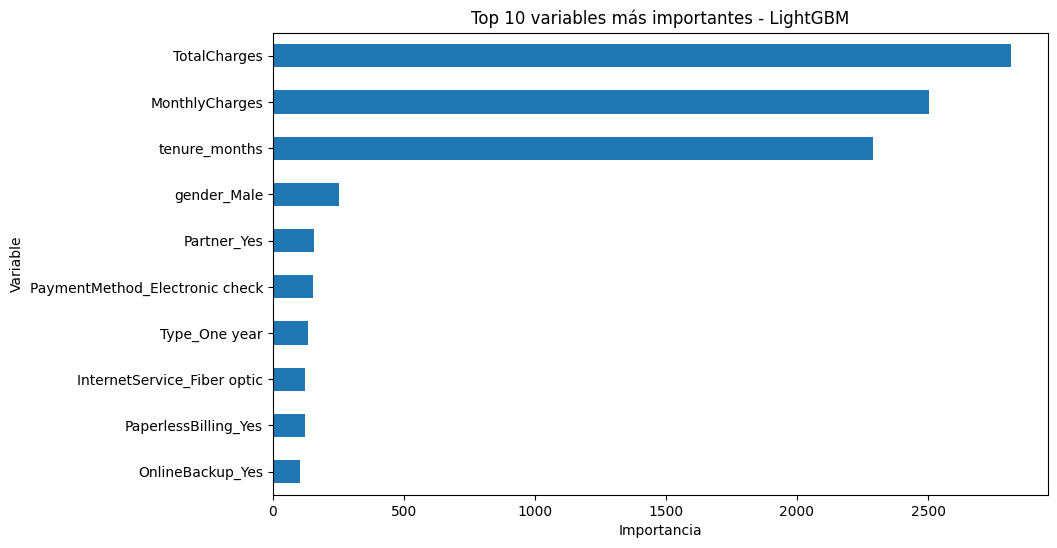

In [86]:
# Gráficamos las variables más importantes
feature_importance.head(10).sort_values().plot(kind='barh', figsize=(10, 6))

plt.title('Top 10 variables más importantes - LightGBM')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.show()

los baselines se calcularon antes de nuestra partición X_train_tune/X_valid, mientras que el modelo final se optimizó utilizando esa validación y finalmente se evaluó en X_test.

In [87]:
# Baseline: Logistic Regression
model_lr_check = LogisticRegression(
    max_iter=1000,
    random_state=12345
)

model_lr_check.fit(X_train, y_train)

y_prob_lr_check = model_lr_check.predict_proba(X_test)[:, 1]
y_pred_lr_check = (y_prob_lr_check >= 0.5).astype(int)

print("AUC:", roc_auc_score(y_test, y_prob_lr_check))
print("Recall:", recall_score(y_test, y_pred_lr_check))
print("F1:", f1_score(y_test, y_pred_lr_check))
print("Accuracy:", accuracy_score(y_test, y_pred_lr_check))
print("Precision:", precision_score(y_test, y_pred_lr_check))

AUC: 0.8301454442119403
Recall: 0.5080213903743316
F1: 0.5663189269746647
Accuracy: 0.7934705464868701
Precision: 0.6397306397306397


c:\Users\alanp\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [88]:
# Baseline: Random Forest
model_rf_check = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=12345
)

model_rf_check.fit(X_train, y_train)

y_prob_rf_check = model_rf_check.predict_proba(X_test)[:, 1]
y_pred_rf_check = (y_prob_rf_check >= 0.5).astype(int)

print("AUC:", roc_auc_score(y_test, y_prob_rf_check))
print("Recall:", recall_score(y_test, y_pred_rf_check))
print("F1:", f1_score(y_test, y_pred_rf_check))
print("Accuracy:", accuracy_score(y_test, y_pred_rf_check))
print("Precision:", precision_score(y_test, y_pred_rf_check))

AUC: 0.854858043349092
Recall: 0.5454545454545454
F1: 0.6144578313253012
Accuracy: 0.8183108587650816
Precision: 0.7034482758620689


In [89]:
# Baseline: LightGBM
model_lgbm_check = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=12345,
    verbosity=-1
)

model_lgbm_check.fit(X_train, y_train)

y_prob_lgbm_check = model_lgbm_check.predict_proba(X_test)[:, 1]
y_pred_lgbm_check = (y_prob_lgbm_check >= 0.5).astype(int)

print("AUC:", roc_auc_score(y_test, y_prob_lgbm_check))
print("Recall:", recall_score(y_test, y_pred_lgbm_check))
print("F1:", f1_score(y_test, y_pred_lgbm_check))
print("Accuracy:", accuracy_score(y_test, y_pred_lgbm_check))
print("Precision:", precision_score(y_test, y_pred_lgbm_check))

AUC: 0.9222144720865949
Recall: 0.6684491978609626
F1: 0.7552870090634441
Accuracy: 0.8850248403122782
Precision: 0.8680555555555556


In [90]:
comparison_final = pd.DataFrame({
    'Modelo': [
        'Logistic Regression',
        'Random Forest',
        'LightGBM baseline',
        'LightGBM optimizado + pesos'
    ],
    'AUC-ROC': [
        0.8251156061897749,
        0.854858043349092,
        0.9222144720865949,
        0.9340205120256271
    ],
    'Recall': [
        0.5026737967914439,
        0.5454545454545454,
        0.6684491978609626,
        0.7834224598930482
    ],
    'F1': [
        0.5637181409295352,
        0.6144578313253011,
        0.7552870090634441,
        0.7865771812080536
    ],
    'Accuracy': [
        0.7934705464868701,
        0.8183108587650816,
        0.8850248403122782,
        0.8871540099361249
    ],
    'Precision': [
        0.6416382252559727,
        0.7034482758620689,
        0.8680555555555556,
        0.7897574123989218
    ]
})

comparison_final

,Modelo,AUC-ROC,Recall,F1,Accuracy,Precision
0,Logistic Regression,0.825116,0.502674,0.563718,0.793471,0.641638
1,Random Forest,0.854858,0.545455,0.614458,0.818311,0.703448
2,LightGBM baseline,0.922214,0.668449,0.755287,0.885025,0.868056
3,LightGBM optimizado + pesos,0.934021,0.783422,0.786577,0.887154,0.789757


# Informe de Solución


1. Objetivo del proyecto

El objetivo fue desarrollar un modelo predictivo capaz de identificar clientes con probabilidad de abandonar los servicios de Interconnect, para que el equipo de marketing pueda dirigir acciones de retención hacia ellos.

El problema se planteó como una clasificación binaria, donde:

0 representa un cliente que permanece activo.
1 representa un cliente que ha abandonado el servicio.

La variable objetivo se construyó a partir de EndDate.

2. Preparación de los datos

Se integró la información proveniente de los archivos de contratos, datos personales, servicios de Internet y servicios telefónicos.

Los valores ausentes relacionados con servicios se interpretaron de acuerdo con el contexto del negocio. Por ejemplo, los valores faltantes en las variables de servicios de Internet se trataron como ausencia de dichos servicios, mientras que los valores faltantes de MultipleLines se interpretaron como ausencia del servicio de líneas múltiples.

Se creó la variable tenure_months para representar la antigüedad del cliente en meses.

Las variables categóricas fueron transformadas mediante One-Hot Encoding y los datos se dividieron en conjuntos de entrenamiento y prueba utilizando una proporción 80/20 y estratificación de la variable objetivo.

3. Modelos evaluados

Se entrenaron tres modelos baseline:

Regresión Logística.
Random Forest.
LightGBM.

Posteriormente se trabajó sobre LightGBM debido a su rendimiento inicial. Se incorporó scale_pos_weight para atender el desbalance de las clases y se realizó una búsqueda de hiperparámetros.

Los resultados obtenidos sobre el mismo conjunto de prueba fueron:

Modelo	                     AUC-ROC	Recall	F1  	Accuracy	Precision
Logistic Regression	          0.8251	0.5027	0.5637	0.7935  	0.6416
Random Forest	              0.8549	0.5455	0.6145	0.8183	    0.7034
LightGBM baseline	          0.9222	0.6684	0.7553	0.8850	    0.8681
LightGBM optimizado + pesos	  0.9340	0.7834	0.7866	0.8872  	0.7898

4. Modelo final

El modelo seleccionado para la solución final fue LightGBM con ajuste de pesos de clase y optimización de hiperparámetros.

La configuración utilizada fue:

n_estimators = 300
learning_rate = 0.10
num_leaves = 50
max_depth = 6
scale_pos_weight = 2.7684

El modelo fue evaluado finalmente sobre el conjunto de prueba, obteniendo:

AUC-ROC: 0.9340
Recall: 0.7834
F1: 0.7866
Accuracy: 0.8872
Precision: 0.7898

El AUC-ROC obtenido supera el mínimo de 0.75 establecido para la aprobación del proyecto.

5. Interpretación desde el punto de vista de negocio

El Recall de 0.7834 significa que el modelo identificó correctamente aproximadamente el 78.3 % de los clientes que efectivamente abandonaron dentro del conjunto de prueba.

En términos de negocio, esto significa que el modelo puede utilizarse para priorizar clientes a los que el equipo de marketing podría dirigir acciones de retención, como promociones o planes especiales.

La matriz de confusión del modelo final fue:

[[957  78]
 [ 81 293]]

De los clientes que abandonaron:

293 fueron identificados correctamente por el modelo.
81 no fueron identificados y constituyeron falsos negativos.

Por lo tanto, aunque el modelo permite identificar una proporción importante de los clientes que abandonan, no detecta todos los casos. Debe utilizarse como una herramienta de apoyo para priorizar acciones de retención y no como una predicción determinista del comportamiento de cada cliente.

6. Variables de mayor importancia

Las variables que presentaron mayor importancia en el modelo final fueron:

TotalCharges
MonthlyCharges
tenure_months
gender_Male
Partner_Yes
PaymentMethod_Electronic check
Type_One year
PaperlessBilling_Yes
InternetService_Fiber optic
OnlineBackup_Yes

Las tres primeras variables presentaron una importancia considerablemente mayor que las siguientes.

Esta información puede ayudar al equipo de marketing a comprender qué características están siendo utilizadas por el modelo para realizar sus predicciones. La importancia de una variable no implica por sí misma causalidad, por lo que estos resultados deben interpretarse como factores utilizados por el modelo y no como causas directas del abandono.

7. Conclusión

El modelo final de LightGBM obtuvo un AUC-ROC de 0.9340 y un Recall de 0.7834 en el conjunto de prueba.

El resultado muestra que el modelo es capaz de discriminar adecuadamente entre clientes que permanecen y clientes que abandonan, y además identifica aproximadamente el 78.3 % de los casos de abandono observados en el conjunto de prueba.

Por ello, el modelo puede incorporarse como una herramienta de apoyo para las estrategias de retención de Interconnect, permitiendo que el equipo de marketing priorice a los clientes con mayor probabilidad de abandono para realizar acciones preventivas.